# Entrenamiento y torneo de modelos

Entrenamiento de seis modelos de regresión para predecir `SalePrice`, con optimización de hiperparámetros mediante validación cruzada de 10 folds. Los modelos se comparan sobre el conjunto de validación con el RMSE en escala real y el RMSE normalizado al rango, y el ganador se guarda como pipeline completo (ingeniería de características + modelo).

El proceso de entrenamiento y el rendimiento de cada modelo se registran en MLflow, y los tres mejores modelos se publican en el Model Registry como champion y challengers (secciones 12 y 13).

**Control de fuga de datos:** se parte de los datos crudos y el preprocesamiento del notebook `2.0-jec-preprocesamiento-modelo` se integra dentro de cada pipeline, de modo que en cada fold se ajusta únicamente con los datos de entrenamiento de ese fold. El conjunto de validación no participa en el entrenamiento ni en la búsqueda de hiperparámetros.

## 1. Librerías

Importación de las librerías de datos y visualización, los transformadores de feature-engine, los modelos y herramientas de validación de sklearn, MLflow para el registro de experimentos y modelos, y el transformador Yeo-Johnson condicional del módulo del proyecto.

In [ ]:
import re
import unicodedata
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from feature_engine.encoding import OrdinalEncoder
from feature_engine.imputation import CategoricalImputer, MeanMedianImputer
from feature_engine.outliers import Winsorizer
from feature_engine.wrappers import SklearnTransformerWrapper
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from proyecto_pd.features import SkewedYeoJohnsonTransformer

## 2. Configuración y carga de datos

Lectura de `pipeline_config.yaml`, definición de rutas y parámetros, configuración de MLflow y carga de `train.csv`. Se usan los mismos `TEST_SIZE` y `RANDOM_STATE` del notebook de preprocesamiento para obtener exactamente la misma partición de validación.

MLflow usa un backend local: los runs y el Model Registry se guardan en `mlflow.db` (SQLite) y los artefactos en `mlruns/`, ambos en la raíz del proyecto y fuera del control de versiones. Para explorarlos, ejecuta en la raíz del proyecto `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000.

In [ ]:
# Rutas configurables: cambia estas variables si las fuentes o destinos se mueven
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODELS_DIR = PROJECT_ROOT / "models"

# Parámetros de partición, preprocesamiento y validación cruzada
TEST_SIZE = 0.2
RANDOM_STATE = 42
IQR_FOLD = 1.5
SKEW_THRESHOLD = 0.75
N_FOLDS = 10

# MLflow: tracking y Model Registry locales
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"
MLFLOW_ARTIFACTS = PROJECT_ROOT / "mlruns"
EXPERIMENT_NAME = "house-pricing-saleprice"
REGISTERED_MODEL_NAME = "house-pricing-saleprice"
N_CHALLENGERS = 2

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=MLFLOW_ARTIFACTS.as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)

with open(CONFIG_FILE, encoding="utf-8") as f:
    config = yaml.safe_load(f)

TARGET = config["TARGET"]
MODEL_FEATURES = config["MODEL_FEATURES"]
CONTINUOUS_FEATURES = config["CONTINUOUS_FEATURES"]
DISCRETE_FEATURES = config["DISCRETE_FEATURES"]
CATEGORICAL_FEATURES = config["CATEGORICAL_FEATURES"]
NUMERIC_FEATURES = CONTINUOUS_FEATURES + DISCRETE_FEATURES

train = pd.read_csv(RAW_DIR / "train.csv")
print(f"train: {train.shape}, features: {len(MODEL_FEATURES)}")
print(f"MLflow: experimento '{EXPERIMENT_NAME}' en {MLFLOW_DB.name}")

## 3. División en entrenamiento y validación

Partición 80/20 idéntica a la del notebook de preprocesamiento. Los modelos se entrenan con el target en escala `log1p`; se conserva el target en escala real para calcular el RMSE real y el rango usado en el RMSE normalizado (rango de `SalePrice` en entrenamiento).

In [4]:
X = train[MODEL_FEATURES]
y_real = train[TARGET]

X_train, X_valid, y_train_real, y_valid_real = train_test_split(
    X, y_real, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train = np.log1p(y_train_real)
y_valid = np.log1p(y_valid_real)

TRAIN_RANGE = y_train_real.max() - y_train_real.min()

print(f"X_train: {X_train.shape}, X_valid: {X_valid.shape}")
print(f"Rango de {TARGET} en entrenamiento: {TRAIN_RANGE:,.0f}")

X_train: (1168, 30), X_valid: (292, 30)
Rango de SalePrice en entrenamiento: 710,100


## 4. Pipeline de ingeniería de características

Reconstrucción del preprocesamiento del notebook `2.0`: imputación categórica (moda), imputación numérica (mediana), codificación ordinal ordenada por el target, capping IQR de continuas, Yeo-Johnson y escalado estándar. Se define como función para crear una instancia nueva por modelo.

La única diferencia es que la selección de variables con |skew| > `SKEW_THRESHOLD` para Yeo-Johnson ocurre dentro de `fit` (`SkewedYeoJohnsonTransformer`), en lugar de calcularse una vez sobre todo el entrenamiento, para que también se decida dentro de cada fold.

In [5]:
def build_fe_steps():
    """Pasos de ingeniería de características, sin ajustar."""
    return [
        ("imputacion_categoricas", CategoricalImputer(imputation_method="frequent", variables=CATEGORICAL_FEATURES)),
        ("imputacion_numericas", MeanMedianImputer(imputation_method="median", variables=NUMERIC_FEATURES)),
        ("codificacion", OrdinalEncoder(encoding_method="ordered", variables=CATEGORICAL_FEATURES, unseen="encode")),
        ("outliers", Winsorizer(capping_method="iqr", tail="both", fold=IQR_FOLD, variables=CONTINUOUS_FEATURES)),
        ("transformacion", SkewedYeoJohnsonTransformer(variables=CONTINUOUS_FEATURES, threshold=SKEW_THRESHOLD)),
        ("escalado", SklearnTransformerWrapper(transformer=StandardScaler(), variables=MODEL_FEATURES)),
    ]


def build_pipeline(model):
    """Pipeline completo: ingeniería de características + modelo."""
    return Pipeline(build_fe_steps() + [("modelo", model)])


build_pipeline(LinearRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion_categoricas', ...), ('imputacion_numericas', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,imputation_method,'frequent'
,variables,"['Neighborhood', 'ExterQual', ...]"
,fill_value,'Missing'
,return_object,False
,ignore_format,False
,variables,"['GrLivArea', 'GarageArea', ...]"
,imputation_method,'median'


## 5. Modelos y grillas de hiperparámetros

Definición de los seis modelos del torneo y de su grilla de búsqueda (al menos tres configuraciones por modelo):

- **Regresiones:** Regresión Lineal (línea base), Ridge (regularización L2) y Lasso (regularización L1).
- **Ensambles:** Random Forest y Gradient Boosting.
- **Red neuronal:** MLPRegressor con `early_stopping`, que reserva una fracción interna del entrenamiento para detener el ajuste cuando deja de mejorar.

Las grillas incluyen parámetros de regularización y complejidad (alpha, profundidad, hojas mínimas, tasa de aprendizaje, submuestreo) para controlar el sobreajuste.

In [6]:
models = {
    "Regresión Lineal": (
        LinearRegression(),
        {"modelo__fit_intercept": [True, False], "modelo__positive": [True, False]},
    ),
    "Ridge": (
        Ridge(random_state=RANDOM_STATE),
        {"modelo__alpha": [0.1, 1, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=20000, random_state=RANDOM_STATE),
        {"modelo__alpha": [0.0001, 0.0005, 0.001, 0.005, 0.01]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {
            "modelo__max_depth": [10, 20, None],
            "modelo__min_samples_leaf": [1, 3, 5],
            "modelo__max_features": [0.33, 1.0],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(n_estimators=500, random_state=RANDOM_STATE),
        {
            "modelo__learning_rate": [0.03, 0.1],
            "modelo__max_depth": [2, 3, 4],
            "modelo__subsample": [0.8, 1.0],
        },
    ),
    "Red Neuronal (MLP)": (
        MLPRegressor(max_iter=2000, early_stopping=True, random_state=RANDOM_STATE),
        {
            "modelo__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
            "modelo__alpha": [0.001, 0.01, 0.1],
            "modelo__learning_rate_init": [0.001, 0.01],
        },
    ),
}

pd.DataFrame(
    {name: {"configuraciones": len(pd.MultiIndex.from_product(grid.values()))} for name, (_, grid) in models.items()}
).T

,configuraciones
Regresión Lineal,4
Ridge,5
Lasso,5
Random Forest,18
Gradient Boosting,12
Red Neuronal (MLP),18


## 6. Validación cruzada y optimización de hiperparámetros

Búsqueda exhaustiva (`GridSearchCV`) con `KFold` de 10 particiones sobre el conjunto de entrenamiento. La métrica de selección es el RMSE en escala `log1p`, la misma escala con la que se entrena. Se registra también el RMSE de entrenamiento de cada fold para comparar contra el de validación cruzada y detectar sobreajuste. Al finalizar, cada búsqueda reentrena la mejor configuración con todo el conjunto de entrenamiento.

In [7]:
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
searches = {}

for name, (model, grid) in models.items():
    search = GridSearchCV(
        build_pipeline(model),
        param_grid=grid,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name}: RMSE CV (log) = {-search.best_score_:.4f} | {search.best_params_}")

Regresión Lineal: RMSE CV (log) = 0.1355 | {'modelo__fit_intercept': True, 'modelo__positive': False}
Ridge: RMSE CV (log) = 0.1352 | {'modelo__alpha': 30}
Lasso: RMSE CV (log) = 0.1353 | {'modelo__alpha': 0.001}
Random Forest: RMSE CV (log) = 0.1369 | {'modelo__max_depth': 20, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
Gradient Boosting: RMSE CV (log) = 0.1313 | {'modelo__learning_rate': 0.03, 'modelo__max_depth': 4, 'modelo__subsample': 0.8}
Red Neuronal (MLP): RMSE CV (log) = 0.4370 | {'modelo__alpha': 0.1, 'modelo__hidden_layer_sizes': (32,), 'modelo__learning_rate_init': 0.01}


## 7. Torneo de modelos en validación

Evaluación de la mejor configuración de cada modelo sobre el conjunto de validación. Las predicciones se revierten a escala real con `expm1` para calcular:

- **RMSE real:** error en dólares.
- **NRMSE:** RMSE real dividido entre el rango de `SalePrice` en entrenamiento.

Para evaluar el sobreajuste se comparan, en escala log, el RMSE de entrenamiento y de validación cruzada (promedio de los folds) con el de validación. Una brecha amplia entre entrenamiento y CV/validación indica que el modelo memoriza los datos.

In [8]:
results = []
predictions = {}

for name, search in searches.items():
    best = search.best_index_
    y_pred_log = search.predict(X_valid)
    y_pred_real = np.expm1(y_pred_log)
    predictions[name] = y_pred_real

    rmse_real = root_mean_squared_error(y_valid_real, y_pred_real)
    results.append({
        "modelo": name,
        "rmse_train_log": -search.cv_results_["mean_train_score"][best],
        "rmse_cv_log": -search.cv_results_["mean_test_score"][best],
        "rmse_valid_log": root_mean_squared_error(y_valid, y_pred_log),
        "rmse_valid_real": rmse_real,
        "nrmse_valid": rmse_real / TRAIN_RANGE,
    })

results_df = (
    pd.DataFrame(results)
    .assign(brecha_train_cv=lambda d: d["rmse_cv_log"] - d["rmse_train_log"])
    .sort_values("rmse_valid_real", ignore_index=True)
)
results_df.style.format({
    "rmse_train_log": "{:.4f}", "rmse_cv_log": "{:.4f}", "rmse_valid_log": "{:.4f}",
    "rmse_valid_real": "{:,.0f}", "nrmse_valid": "{:.4f}", "brecha_train_cv": "{:.4f}",
})

,modelo,rmse_train_log,rmse_cv_log,rmse_valid_log,rmse_valid_real,nrmse_valid,brecha_train_cv
0,Gradient Boosting,0.0509,0.1313,0.1446,"27,719",0.0390,0.0804
1,Random Forest,0.0520,0.1369,0.1503,"28,732",0.0405,0.0849
2,Ridge,0.1324,0.1352,0.1457,"29,078",0.0409,0.0028
3,Regresión Lineal,0.1322,0.1355,0.1454,"29,208",0.0411,0.0033
4,Lasso,0.1323,0.1353,0.1454,"29,250",0.0412,0.0030
5,Red Neuronal (MLP),0.1939,0.4370,0.2182,"43,987",0.0619,0.2430


## 8. Gráficas de desempeño por modelo

Para cada modelo, sobre el conjunto de validación y en escala real:

- **Real vs predicho:** los puntos deben ubicarse cerca de la línea ideal y = x.
- **Residuos vs predicho:** los residuos deben distribuirse alrededor de cero sin patrones; un embudo o una curva indican errores sistemáticos.
- **Distribución de residuos:** se espera una forma centrada en cero y aproximadamente simétrica.

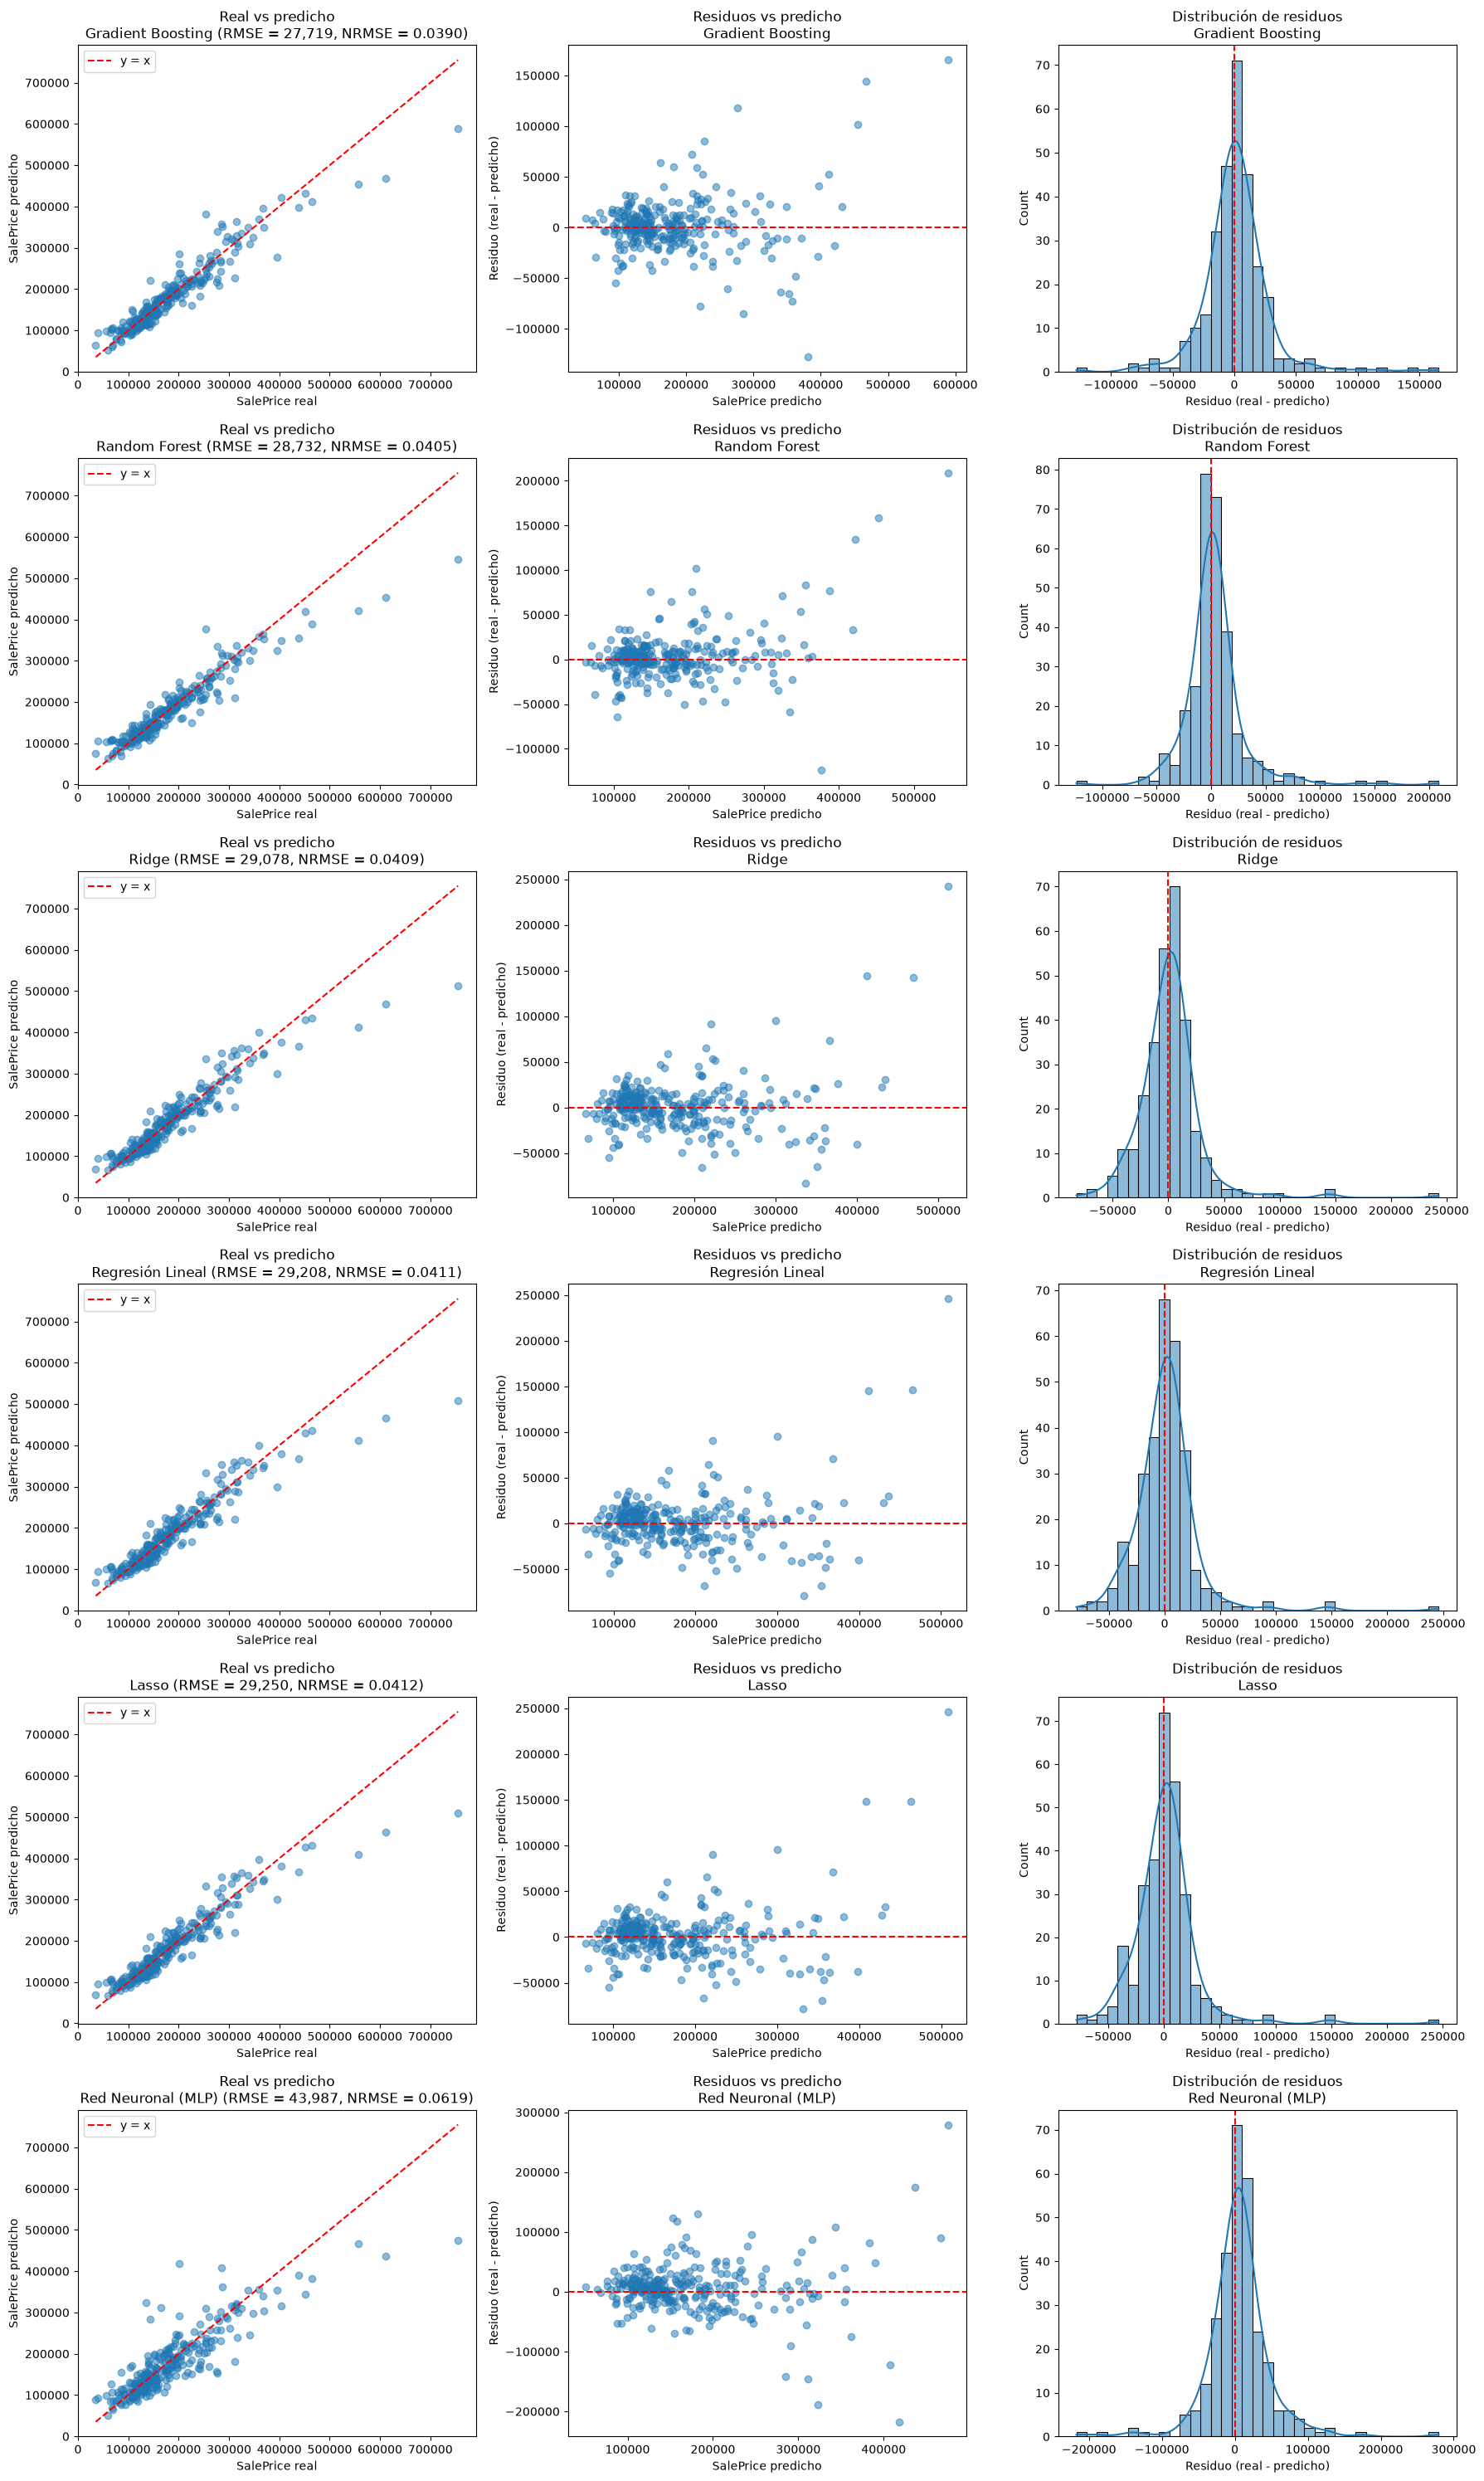

In [9]:
metrics = results_df.set_index("modelo")
fig, axes = plt.subplots(len(predictions), 3, figsize=(18, 5 * len(predictions)))

for row, name in zip(axes, metrics.index):
    y_pred = predictions[name]
    residuals = y_valid_real - y_pred
    label = f"{name} (RMSE = {metrics.loc[name, 'rmse_valid_real']:,.0f}, NRMSE = {metrics.loc[name, 'nrmse_valid']:.4f})"

    limits = [min(y_valid_real.min(), y_pred.min()), max(y_valid_real.max(), y_pred.max())]
    row[0].scatter(y_valid_real, y_pred, alpha=0.5)
    row[0].plot(limits, limits, color="red", linestyle="--", label="y = x")
    row[0].set_title(f"Real vs predicho\n{label}")
    row[0].set_xlabel(f"{TARGET} real")
    row[0].set_ylabel(f"{TARGET} predicho")
    row[0].legend()

    row[1].scatter(y_pred, residuals, alpha=0.5)
    row[1].axhline(0, color="red", linestyle="--")
    row[1].set_title(f"Residuos vs predicho\n{name}")
    row[1].set_xlabel(f"{TARGET} predicho")
    row[1].set_ylabel("Residuo (real - predicho)")

    sns.histplot(residuals, kde=True, ax=row[2])
    row[2].axvline(0, color="red", linestyle="--")
    row[2].set_title(f"Distribución de residuos\n{name}")
    row[2].set_xlabel("Residuo (real - predicho)")

plt.tight_layout()
plt.show()

## 9. Selección y guardado del modelo ganador

El ganador es el modelo con menor RMSE real en validación. Se guarda su pipeline completo (ingeniería de características + modelo), ajustado con el conjunto de entrenamiento, en `models/`. El pipeline recibe datos crudos con las columnas de `MODEL_FEATURES` y devuelve predicciones en escala `log1p`, que deben revertirse con `np.expm1`.

In [12]:
winner = results_df.loc[0, "modelo"]
winner_pipeline = searches[winner].best_estimator_

MODELS_DIR.mkdir(parents=True, exist_ok=True)
winner_file = MODELS_DIR / "best_model_pipeline.joblib"
joblib.dump(winner_pipeline, winner_file)

print(f"Ganador: {winner}")
print(f"Hiperparámetros: {searches[winner].best_params_}")
print(f"RMSE real: {results_df.loc[0, 'rmse_valid_real']:,.0f} | NRMSE: {results_df.loc[0, 'nrmse_valid']:.4f}")
print(f"Guardado en: {winner_file.relative_to(PROJECT_ROOT)}")

Ganador: Gradient Boosting
Hiperparámetros: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 4, 'modelo__subsample': 0.8}
RMSE real: 27,719 | NRMSE: 0.0390
Guardado en: models\best_model_pipeline.joblib


## 10. Reentrenamiento del modelo ganador para producción

Una vez seleccionado el ganador y validado su desempeño, se reentrena una copia sin ajustar de su pipeline completo (ingeniería de características + modelo, con los mismos hiperparámetros) usando el 100 % de `train.csv` (entrenamiento + validación), para aprovechar todos los datos disponibles. No se recalculan métricas, ya que la validación ahora forma parte del entrenamiento; la estimación de desempeño es la obtenida en la sección 7.

El pipeline final se guarda en `models/final_model_pipeline.joblib`, recibe datos crudos con las columnas de `MODEL_FEATURES` y devuelve predicciones en escala `log1p`. El archivo `best_model_pipeline.joblib` (ajustado con el 80 %) se conserva como referencia de la evaluación.

In [18]:
from sklearn.base import clone

final_pipeline = clone(winner_pipeline)
final_pipeline.fit(X, np.log1p(y_real))

final_file = MODELS_DIR / "final_model_pipeline.joblib"
joblib.dump(final_pipeline, final_file)

print(f"Modelo final: {winner} entrenado con {len(X)} registros")
print(f"Guardado en: {final_file.relative_to(PROJECT_ROOT)}")
final_pipeline

Modelo final: Gradient Boosting entrenado con 1460 registros
Guardado en: models\final_model_pipeline.joblib


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion_categoricas', ...), ('imputacion_numericas', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,imputation_method,'frequent'
,variables,"['Neighborhood', 'ExterQual', ...]"
,fill_value,'Missing'
,return_object,False


## 11. Criterios de descarte y exportación de resultados

Evaluación de la coherencia de cada modelo y exportación de los resultados del torneo a `reports/model_results.json`, que alimenta el reporte interactivo de desempeño. Cada modelo usa su mejor configuración ajustada con el 80 % para predecir validación y `test.csv`; sus predicciones de test se comparan contra las del pipeline de inferencia (modelo final) y contra la distribución real de `SalePrice` en entrenamiento.

Un modelo se marca como **descartado** si cumple al menos uno de estos criterios:

- **Predicciones inválidas:** nulos, negativos o infinitos en validación o test.
- **Error muy alto:** RMSE real en validación mayor a `MAX_RMSE_RATIO` veces el del mejor modelo.
- **Sobreajuste:** RMSE de validación cruzada menos RMSE de entrenamiento (escala log) mayor a `MAX_OVERFIT_GAP`.
- **Salida fuera de rango:** mediana de las predicciones de test a más de `MAX_MEDIAN_DEVIATION` de la mediana real de entrenamiento, o más de `MAX_OUT_OF_RANGE` de las predicciones fuera del rango [mínimo, máximo] de entrenamiento.

El descarte solo se registra en el reporte; no modifica la selección del ganador de la sección 9.

In [ ]:
import json

REPORTS_DIR = PROJECT_ROOT / "reports"
RESULTS_FILE = REPORTS_DIR / "model_results.json"

# Umbrales de descarte
MAX_RMSE_RATIO = 2.0
MAX_OVERFIT_GAP = 0.05
MAX_MEDIAN_DEVIATION = 0.20
MAX_OUT_OF_RANGE = 0.01

test = pd.read_csv(RAW_DIR / "test.csv")
X_test = test[MODEL_FEATURES]
inference_test = np.expm1(final_pipeline.predict(X_test))

train_median, train_min, train_max = y_real.median(), y_real.min(), y_real.max()
best_rmse = results_df["rmse_valid_real"].min()


def to_list(values, decimals=0):
    """Convierte a lista serializable en JSON; los valores no finitos quedan como null."""
    return [round(float(v), decimals) if np.isfinite(v) else None for v in np.asarray(values, dtype=float)]


def discard_reasons(row, valid_pred, test_pred):
    """Lista de criterios de descarte que cumple un modelo."""
    reasons = []
    all_pred = np.concatenate([valid_pred, test_pred])
    if not (np.isfinite(all_pred).all() and (all_pred > 0).all()):
        reasons.append("Predicciones inválidas: nulos, negativos o infinitos")
    if row["rmse_valid_real"] > MAX_RMSE_RATIO * best_rmse:
        reasons.append(f"Error muy alto: RMSE real {row['rmse_valid_real']:,.0f} > {MAX_RMSE_RATIO:g}× el mejor ({best_rmse:,.0f})")
    if row["brecha_train_cv"] > MAX_OVERFIT_GAP:
        reasons.append(f"Sobreajuste: brecha CV − train {row['brecha_train_cv']:.4f} > {MAX_OVERFIT_GAP}")
    with np.errstate(invalid="ignore"):
        median_dev = abs(np.nanmedian(test_pred) / train_median - 1)
        out_of_range = np.mean((test_pred < train_min) | (test_pred > train_max) | ~np.isfinite(test_pred))
    if not median_dev <= MAX_MEDIAN_DEVIATION:
        reasons.append(f"Salida fuera de rango: mediana de test a {median_dev:.1%} de la mediana de train")
    if out_of_range > MAX_OUT_OF_RANGE:
        reasons.append(f"Salida fuera de rango: {out_of_range:.1%} de predicciones de test fuera de [mín, máx] de train")
    return reasons


export_models = []
for _, row in results_df.iterrows():
    name = row["modelo"]
    search = searches[name]
    with np.errstate(over="ignore"):
        test_pred = np.expm1(search.predict(X_test))
    valid_pred = predictions[name]
    reasons = discard_reasons(row, valid_pred, test_pred)
    finite = np.isfinite(test_pred)

    cv_df = pd.DataFrame(search.cv_results_)
    export_models.append({
        "name": name,
        "best_params": {k.replace("modelo__", ""): v for k, v in search.best_params_.items()},
        "metrics": {k: float(row[k]) for k in ["rmse_train_log", "rmse_cv_log", "rmse_valid_log", "rmse_valid_real", "nrmse_valid", "brecha_train_cv"]},
        "test_summary": {
            "median": float(np.median(test_pred[finite])) if finite.any() else None,
            "min": float(test_pred[finite].min()) if finite.any() else None,
            "max": float(test_pred[finite].max()) if finite.any() else None,
            "corr_inference": float(np.corrcoef(test_pred[finite], inference_test[finite])[0, 1]) if finite.sum() > 1 else None,
        },
        "cv_results": [
            {
                "params": ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in p.items()),
                "rmse_cv": float(-m), "rmse_cv_std": float(s), "rmse_train": float(-t), "rank": int(r),
            }
            for p, m, s, t, r in zip(
                cv_df["params"], cv_df["mean_test_score"], cv_df["std_test_score"], cv_df["mean_train_score"], cv_df["rank_test_score"]
            )
        ],
        "discarded": bool(reasons),
        "discard_reasons": reasons,
        "valid_pred": to_list(valid_pred),
        "test_pred": to_list(test_pred),
    })

export = {
    "meta": {
        "target": TARGET,
        "n_folds": N_FOLDS,
        "n_train": len(X_train),
        "n_valid": len(X_valid),
        "n_test": len(X_test),
        "train_range": float(TRAIN_RANGE),
        "train_median": float(train_median),
        "train_min": float(train_min),
        "train_max": float(train_max),
        "winner": winner,
        "thresholds": {
            "max_rmse_ratio": MAX_RMSE_RATIO,
            "max_overfit_gap": MAX_OVERFIT_GAP,
            "max_median_deviation": MAX_MEDIAN_DEVIATION,
            "max_out_of_range": MAX_OUT_OF_RANGE,
        },
    },
    "train_target": to_list(y_real),
    "valid_real": to_list(y_valid_real),
    "inference_test": to_list(inference_test),
    "models": export_models,
}

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULTS_FILE, "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False)

print(f"Resultados exportados a {RESULTS_FILE.relative_to(PROJECT_ROOT)}")
pd.DataFrame(
    {m["name"]: {"descartado": m["discarded"], "motivos": "; ".join(m["discard_reasons"]) or "—"} for m in export_models}
).T

## 12. Registro del torneo en MLflow

Registro del proceso de entrenamiento y del rendimiento de cada modelo en el experimento `house-pricing-saleprice`:

- **Run padre del torneo:** parámetros generales (folds, partición, preprocesamiento), `pipeline_config.yaml` y la tabla de resultados de los seis modelos.
- **Un run hijo por modelo:** hiperparámetros de la mejor configuración; métricas de entrenamiento, validación cruzada y validación (RMSE log, RMSE real, NRMSE, brecha CV − train) y de su salida en test; estado según los criterios de descarte de la sección 11; la tabla con todas las configuraciones probadas en la búsqueda en grilla y las gráficas real vs predicho y de residuos en validación.

Los identificadores de los runs hijos se guardan en `model_runs` para asociarles después los modelos registrados.

In [ ]:
def validation_figure(name, y_true, y_pred):
    """Real vs predicho y residuos vs predicho en validación."""
    residuals = y_true - y_pred
    limits = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_true, y_pred, alpha=0.5)
    axes[0].plot(limits, limits, color="red", linestyle="--", label="y = x")
    axes[0].set_title(f"Real vs predicho — {name}")
    axes[0].set_xlabel(f"{TARGET} real")
    axes[0].set_ylabel(f"{TARGET} predicho")
    axes[0].legend()
    axes[1].scatter(y_pred, residuals, alpha=0.5)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_title(f"Residuos vs predicho — {name}")
    axes[1].set_xlabel(f"{TARGET} predicho")
    axes[1].set_ylabel("Residuo (real - predicho)")
    fig.tight_layout()
    return fig


export_by_name = {m["name"]: m for m in export_models}
metrics_by_name = results_df.set_index("modelo")
model_runs = {}

with mlflow.start_run(run_name=f"torneo-{pd.Timestamp.now():%Y%m%d-%H%M%S}") as tournament_run:
    mlflow.set_tags({"etapa": "entrenamiento", "ganador": winner})
    mlflow.log_params({
        "n_folds": N_FOLDS, "test_size": TEST_SIZE, "random_state": RANDOM_STATE,
        "iqr_fold": IQR_FOLD, "skew_threshold": SKEW_THRESHOLD, "n_features": len(MODEL_FEATURES),
        "n_train": len(X_train), "n_valid": len(X_valid), "target_transform": "log1p",
    })
    mlflow.log_artifact(str(CONFIG_FILE))
    mlflow.log_table(results_df, artifact_file="torneo/resultados.json")

    for name, search in searches.items():
        exported = export_by_name[name]
        row = metrics_by_name.loc[name]
        with mlflow.start_run(run_name=name, nested=True) as model_run:
            mlflow.set_tags({
                "model_type": name,
                "estado": "Descartado" if exported["discarded"] else "Vigente",
                "motivos_descarte": "; ".join(exported["discard_reasons"]) or "ninguno",
            })
            mlflow.log_params({k.replace("modelo__", ""): v for k, v in search.best_params_.items()})
            mlflow.log_param("n_configuraciones", len(search.cv_results_["params"]))
            mlflow.log_metrics({k: float(row[k]) for k in [
                "rmse_train_log", "rmse_cv_log", "rmse_valid_log", "rmse_valid_real", "nrmse_valid", "brecha_train_cv"
            ]})
            mlflow.log_metric("rmse_cv_std_log", float(search.cv_results_["std_test_score"][search.best_index_]))
            mlflow.log_metrics({
                f"test_{k}": float(v) for k, v in exported["test_summary"].items() if v is not None
            })

            grid = pd.DataFrame(search.cv_results_)
            grid = pd.DataFrame({
                "configuracion": grid["params"].map(lambda p: ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in p.items())),
                "rmse_cv_log": -grid["mean_test_score"],
                "rmse_cv_std_log": grid["std_test_score"],
                "rmse_train_log": -grid["mean_train_score"],
                "rank": grid["rank_test_score"],
            }).sort_values("rank")
            mlflow.log_table(grid, artifact_file="grid/configuraciones.json")

            fig = validation_figure(name, y_valid_real.to_numpy(), predictions[name])
            mlflow.log_figure(fig, "graficas/validacion.png")
            plt.close(fig)

            model_runs[name] = model_run.info.run_id

print(f"Run del torneo: {tournament_run.info.run_id}")
pd.Series(model_runs, name="run_id").to_frame()

## 13. Registro del champion y los challengers

Los tres mejores modelos por RMSE real en validación se registran como versiones del modelo `house-pricing-saleprice` en el Model Registry. El primero es el **champion** y los dos siguientes son **challengers**, sin importar su estado de descarte.

- **Versión registrada:** cada uno se reentrena con su mejor configuración sobre el 100 % de `train.csv` (pipeline completo de ingeniería de características + modelo), igual que el modelo final de la sección 10. Sus métricas de desempeño son las de validación registradas en su run.
- **Aliases con el nombre del modelo:** `champion-<modelo>`, `challenger-1-<modelo>` y `challenger-2-<modelo>` (por ejemplo, `champion-gradient-boosting`). Antes de asignarlos se eliminan los aliases de una ejecución anterior, de modo que siempre haya un solo champion y dos challengers.
- **Metadatos de la versión:** tags con el tipo de modelo, su rol, estado y métricas, y una descripción legible.
- **Serialización:** MLflow guarda los modelos con skops, que solo carga clases declaradas como confiables; `SKOPS_TRUSTED_TYPES` lista los transformadores de feature-engine, el transformador del proyecto y la estructura de árbol de sklearn que usan estos pipelines.
- **Firma:** las columnas enteras se declaran como decimales en la firma, ya que en `test.csv` pueden llegar con valores faltantes.

El modelo registrado recibe datos crudos con las columnas de `MODEL_FEATURES` y predice en escala `log1p`.

In [ ]:
SKOPS_TRUSTED_TYPES = [
    "feature_engine.encoding.ordinal.OrdinalEncoder",
    "feature_engine.imputation.categorical.CategoricalImputer",
    "feature_engine.imputation.mean_median.MeanMedianImputer",
    "feature_engine.outliers.winsorizer.Winsorizer",
    "feature_engine.transformation.yeojohnson.YeoJohnsonTransformer",
    "feature_engine.wrappers.wrappers.SklearnTransformerWrapper",
    "proyecto_pd.features.SkewedYeoJohnsonTransformer",
    "sklearn.tree._tree.Tree",
]


def alias_slug(text):
    """Nombre del modelo en minúsculas, sin acentos y con guiones, válido para un alias."""
    ascii_text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "-", ascii_text.lower()).strip("-")


client = MlflowClient()
roles = ["champion"] + [f"challenger-{i}" for i in range(1, N_CHALLENGERS + 1)]
ranking = results_df.sort_values("rmse_valid_real")["modelo"].head(len(roles)).tolist()

# Elimina los aliases de una ejecución anterior
if client.search_registered_models(filter_string=f"name = '{REGISTERED_MODEL_NAME}'"):
    for old_alias in client.get_registered_model(REGISTERED_MODEL_NAME).aliases:
        client.delete_registered_model_alias(REGISTERED_MODEL_NAME, old_alias)

X_signature = X.astype({col: "float64" for col in X.select_dtypes("integer").columns})
registered = []

for role, name in zip(roles, ranking):
    production_pipeline = clone(searches[name].best_estimator_).fit(X, np.log1p(y_real))
    with mlflow.start_run(run_id=model_runs[name]):
        mlflow.set_tag("rol", role)
        model_info = mlflow.sklearn.log_model(
            production_pipeline,
            name="model",
            signature=infer_signature(X_signature, production_pipeline.predict(X)),
            input_example=X_signature.head(3),
            registered_model_name=REGISTERED_MODEL_NAME,
            skops_trusted_types=SKOPS_TRUSTED_TYPES,
        )

    version = model_info.registered_model_version
    alias = f"{role}-{alias_slug(name)}"
    row = metrics_by_name.loc[name]
    exported = export_by_name[name]
    client.set_registered_model_alias(REGISTERED_MODEL_NAME, alias, version)
    for key, value in {
        "model_type": name,
        "rol": role,
        "estado": "Descartado" if exported["discarded"] else "Vigente",
        "rmse_valid_real": f"{row['rmse_valid_real']:.0f}",
        "nrmse_valid": f"{row['nrmse_valid']:.4f}",
        "rmse_cv_log": f"{row['rmse_cv_log']:.4f}",
        "entrenado_con": f"100% de train.csv ({len(X)} registros)",
    }.items():
        client.set_model_version_tag(REGISTERED_MODEL_NAME, version, key, value)
    client.update_model_version(
        REGISTERED_MODEL_NAME, version,
        description=(
            f"{name} ({role}). Mejor configuración: {exported['best_params']}. "
            f"RMSE real en validación {row['rmse_valid_real']:,.0f}, NRMSE {row['nrmse_valid']:.4f}. "
            f"Reentrenado con el 100% de train.csv; predice SalePrice en escala log1p."
        ),
    )
    registered.append({"rol": role, "alias": alias, "modelo": name, "version": version,
                       "rmse_valid_real": round(row["rmse_valid_real"]), "run_id": model_runs[name]})

pd.DataFrame(registered)